# Act 1 · Lab 1: Build a Spark Declarative Pipeline with Genie Code

You are a data engineer at **NovaBrand**, a CPG company that sells through major US retailers. Business users want answers without filing tickets. Your job in Act 1 is to build the data foundation they will use in Acts 2 and 3.

In this lab you give Genie Code one prompt. It explores the raw Crisp tables, designs a **bronze → silver → gold** Lakeflow Spark Declarative Pipeline, writes the SQL, creates the pipeline and runs it.

| Lab | Notebook | You build |
| --- | --- | --- |
| **1** | `01_build_sdp` (this one) | Spark Declarative Pipeline with 3 gold tables |
| 2 (optional) | `Optional_02_AIBI_Dashboard` | AI/BI dashboard: **Crisp Retail Analytics** |


<div style="border-left: 6px solid #FF3621; background: #FFF1EE; color: #1B3139; padding: 12px 16px; border-radius: 6px;">
<b>Before you start: run this notebook on Serverless, environment version 6</b><br/>
Attach <b>Serverless</b>, set the base environment to <b>Standard v6</b>, then click <b>Apply</b>. Steps 1 to 5 below show where to click.
</div>

### Attach Serverless compute

1. At the top of the notebook, click the compute drop-down and select **Serverless**.
2. Check that the Serverless entry says **Environment version 6**. Point at the arrow on its right to open its menu.
3. Click **Configuration**. The Environment panel opens on the right.
4. Under **Environment > Base environment**, select **Standard v6** (Python 3.12). Leave Accelerator and Memory as they are.

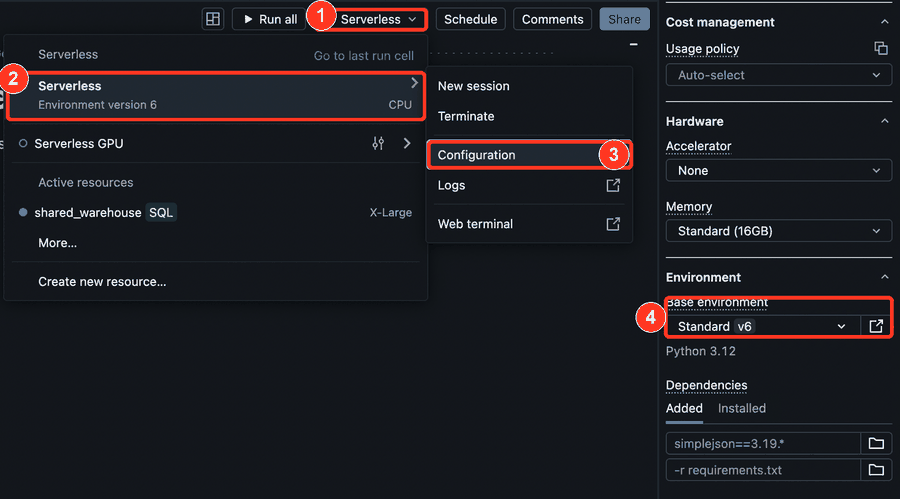

5. Click **Apply**. Databricks installs the environment and restarts Python, so wait for it to finish before you run the next cell.

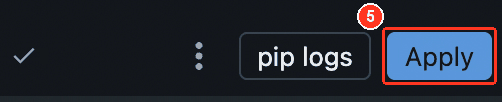

Docs: [Serverless compute for notebooks](https://docs.databricks.com/aws/en/compute/serverless/notebooks), [Serverless environment versions](https://docs.databricks.com/aws/en/release-notes/serverless/environment-version/)

## Open Genie Code

Click the Genie Code icon in the upper-right corner of the notebook to open the Genie Code pane:

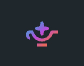

Use **full page Genie Code** for this lab. Open it either way:
- On the workspace home page, select **Code** in the prompt box, type your prompt and submit it.
- In the Genie Code pane, click **Maximize**.

Full page Genie Code runs chats in parallel and opens the files it creates as tabs next to the chat. The pane works too if you prefer it.

### Pick the effort level

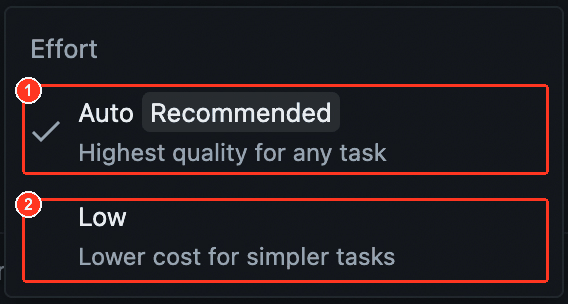

1. **Auto** (recommended) gives the highest quality for any task. Use it for this lab, because a pipeline takes many steps.
2. **Low** lowers the cost for simpler tasks, for example explaining a cell or renaming a column.

### The + menu in the chat box

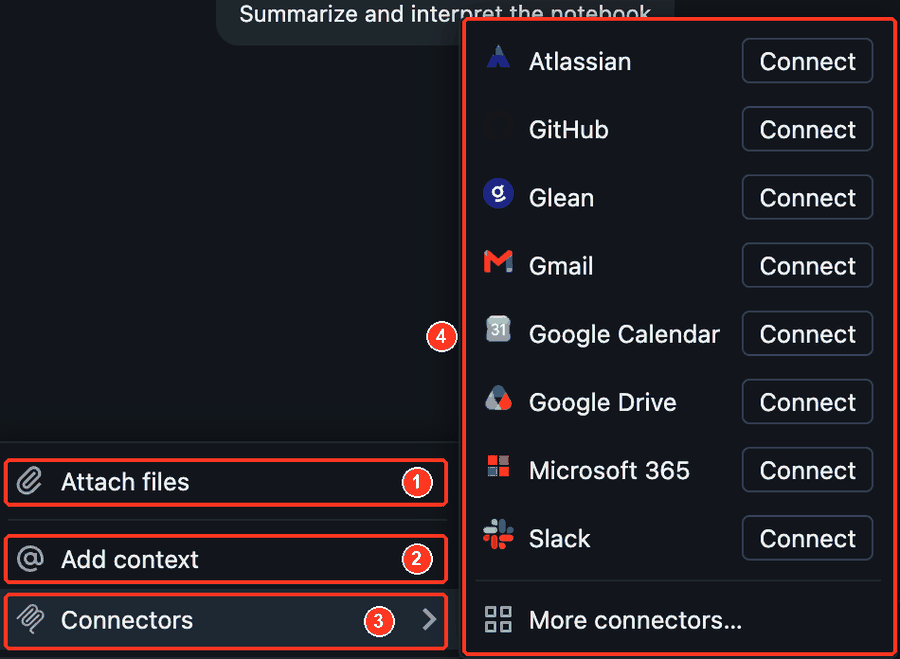

1. **Attach files**: add a file from your laptop to the chat, such as a CSV sample or a screenshot of an error.
2. **Add context**: point Genie Code at a table, notebook or file in the workspace. Typing `@` in the chat does the same.
3. **Connectors**: link Genie Code to tools outside Databricks.
4. The connectors your workspace admin has approved. You sign in to each one yourself before Genie Code can use it. This lab does not need any connectors.

Docs: [Navigate Genie Code](https://docs.databricks.com/aws/en/genie-code/navigate-genie-code), [Full page Genie Code](https://docs.databricks.com/aws/en/genie-code/full-page), [Connect tools to Genie Code](https://docs.databricks.com/aws/en/genie-code/mcp)

## Set Genie Code to ask before it acts

Do this once, before you start the chat for this lab.

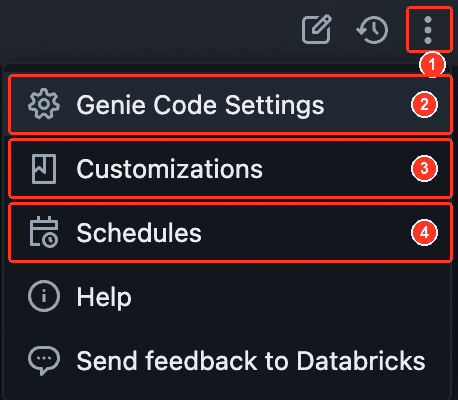

1. In the Genie Code pane, click the **⋮** menu.
2. **Genie Code Settings** holds the approval mode. Open it now.
3. **Customizations** holds your skills and instructions. You use it later in this notebook.
4. **Schedules** runs a prompt on a timer. You use it at the end of this notebook.

Under **Actions**, select **Ask first**:

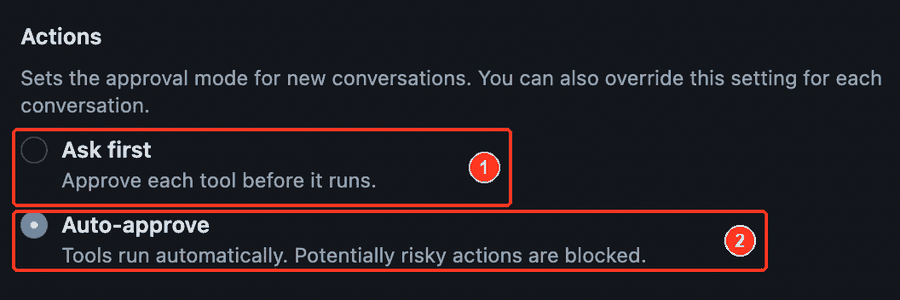

1. **Ask first**: Genie Code stops before each tool call, such as running a SQL query, writing a file or creating the pipeline, and waits for you to approve it.
2. **Auto-approve**: tools run without stopping. Genie Code still blocks actions it rates as risky, for example dropping a table you did not name or changing permissions. Auto-approve is the default the first time you use Genie Code.

**Why Ask first for this lab:** you see each step Genie Code takes and the SQL it writes, so you learn how it builds the pipeline and you can stop a wrong step before it runs. If you prefer fewer clicks, pick **Auto-approve**. The setting applies to new conversations, and you can change it for a single chat at any time.

Docs: [Navigate Genie Code](https://docs.databricks.com/aws/en/genie-code/navigate-genie-code)

In [0]:
# Run this cell first. It works out the two names the prompt needs,
# checks that they exist, and prints the prompt with your names filled in.

# SOURCE_SCHEMA = "crisp_retail_distribution_data.examples" 

SOURCE_SCHEMA = "crisp_inc_cpg_retail_and_distributor_data_samples.examples"  # the Crisp tables, read only

TARGET_CATALOG = "genie_workshop_catalog"                   # your schema lives in this catalog
PIPELINE_PREFIX = "CPG Retail Analytics Pipeline"           # your user name is added, see below
SOURCE_TABLES = [
    "harmonized_retailer_sales",
    "harmonized_retailer_inventory_store",
    "harmonized_retailer_inventory_dc",
]

PROMPT_TEMPLATE = """Create a Lakeflow Spark Declarative Pipeline called "<pipeline_name>" that reads from these 3 raw tables in <source_schema>:
- harmonized_retailer_sales
- harmonized_retailer_inventory_store
- harmonized_retailer_inventory_dc

Publish to <target_schema>.

Build a bronze → silver → gold medallion architecture:
- Bronze: ingest each source table as-is
- Silver: create dimension tables (product, store, distribution center) and fact tables (daily sales, daily store inventory, daily DC inventory)
- Gold: build 3 analytics-ready tables with exactly these names:
  1. gold_sales_velocity: weekly sales rate per product × store
  2. gold_inventory_health: days of supply and stock status per product × store
  3. gold_supply_chain_coverage: DC-to-store fill rates per product × retailer × month

Run the pipeline when done."""

user = spark.sql("SELECT current_user()").first()[0]       # labuser..._...@vocareum.com
source_schema = SOURCE_SCHEMA
schema_name = user.split("@")[0].replace(".", "_")         # first.last becomes first_last
target_schema = f"{TARGET_CATALOG}.{schema_name}"       # genie_workshop_catalog.labuser..._...
# Pipeline names must be unique in a workspace, and other participants use this workspace too.
pipeline_name = f"{PIPELINE_PREFIX} ({schema_name})"


def schema_found(full_name):
    try:
        catalog, schema = full_name.split(".", 1)
        return len(spark.sql(f"SHOW SCHEMAS IN `{catalog}` LIKE '{schema}'").collect()) > 0
    except Exception:
        return False


def table_found(full_name):
    try:
        return spark.catalog.tableExists(full_name)
    except Exception:
        try:
            spark.sql(f"DESCRIBE TABLE {full_name}").collect()
            return True
        except Exception:
            return False


problems = []
if not schema_found(target_schema):
    problems.append(f"Target schema {target_schema} NOT FOUND")
for table in SOURCE_TABLES:
    if not table_found(f"{source_schema}.{table}"):
        problems.append(f"Source table {source_schema}.{table} NOT FOUND")

print(f"You are:        {user}")
print(f"Source schema:  {source_schema}")
print(f"Target schema:  {target_schema}")
print(f"Pipeline name:  {pipeline_name}")
if problems:
    print("\nAsk a TA before you continue:")
    for problem in problems:
        print(f"  - {problem}")
else:
    print("\nOK: your target schema and all 3 source tables exist.")

print("\nCopy everything between the lines into Genie Code:\n" + "-" * 72)
print(PROMPT_TEMPLATE.replace("<pipeline_name>", pipeline_name)
      .replace("<source_schema>", source_schema)
      .replace("<target_schema>", target_schema))
print("-" * 72)

---
## Prompt to give Genie Code

The cell above printed this prompt with your own `<pipeline_name>`, `<source_schema>` and `<target_schema>` filled in. Copy it from the cell output and paste it into Genie Code. The template below shows what the prompt asks for.

The pipeline name ends with your user name because pipeline names must be unique in a workspace, and other participants use this workspace too.

---

````
Create a Lakeflow Spark Declarative Pipeline called "<pipeline_name>" that reads from these 3 raw tables in <source_schema>:
- harmonized_retailer_sales
- harmonized_retailer_inventory_store
- harmonized_retailer_inventory_dc

Publish to <target_schema>.

Build a bronze → silver → gold medallion architecture:
- Bronze: ingest each source table as-is
- Silver: create dimension tables (product, store, distribution center) and fact tables (daily sales, daily store inventory, daily DC inventory)
- Gold: build 3 analytics-ready tables with exactly these names:
  1. gold_sales_velocity: weekly sales rate per product × store
  2. gold_inventory_health: days of supply and stock status per product × store
  3. gold_supply_chain_coverage: DC-to-store fill rates per product × retailer × month

Run the pipeline when done.
````

### What to expect

Genie Code will:
1. **Explore the source tables**: read schemas, sample rows and work out the grain of each table
2. **Create the pipeline** with your target catalog and schema
3. **Write the SQL files** for bronze, silver and gold, organized in folders
4. **Run the pipeline** and wait for the update to finish

With **Ask first** on, Genie Code stops before each step. Read what it plans to do, then click **Allow**. Pick **Always allow in current thread** if you trust the plan and want it to keep going. With **Auto-approve** on, it runs the steps without stopping, so watch the chat as it works.

The raw sales table has about 717M rows, so the first run takes several minutes.

### Expected output

A pipeline with a folder structure similar to this one. Genie Code creates the `transformations/` folder by default. It picks the subfolders and file names itself, so yours can differ.

```
transformations/
  bronze/
    bronze_sales.sql
    bronze_inventory_store.sql
    bronze_inventory_dc.sql
  silver/
    dim_product.sql
    dim_store.sql
    dim_distribution_center.sql
    fact_daily_sales.sql
    fact_daily_store_inventory.sql
    fact_daily_dc_inventory.sql
  gold/
    gold_sales_velocity.sql
    gold_inventory_health.sql
    gold_supply_chain_coverage.sql
```

And three gold tables in your target schema:

| Table | Grain | 
| --- | --- | 
| `gold_sales_velocity` | product × store × week | 
| `gold_inventory_health` | product × store | 
| `gold_supply_chain_coverage` | product × retailer × month | 

> Columns and SQL logic vary between runs, because Genie Code makes its own design choices from what it finds in the data. The three gold table names should match, because the prompt fixes them. Run the next cell to check.

In [0]:
# Run this cell after the pipeline update finishes.
# It checks that the three gold tables exist in your schema and counts their rows.

TARGET_CATALOG = "genie_workshop_catalog"
GOLD_TABLES = ["gold_sales_velocity", "gold_inventory_health", "gold_supply_chain_coverage"]

user = spark.sql("SELECT current_user()").first()[0]
target_schema = f"{TARGET_CATALOG}.{user.split('@')[0].replace('.', '_')}"

missing = 0
for table in GOLD_TABLES:
    name = f"{target_schema}.{table}"
    try:
        exists = spark.catalog.tableExists(name)
    except Exception:
        exists = False
    if exists:
        print(f"OK       {name}: {spark.table(name).count():,} rows")
    else:
        missing += 1
        print(f"MISSING  {name}")

if missing:
    print(f"\n{missing} gold table(s) missing. Ask Genie Code: "
          "\"List the tables the pipeline created and fix the gold table names.\"")
else:
    print("\nAll three gold tables are ready.")

---
## Iterate on the gold layer

Treat the first gold layer as a draft. Stay in the same chat and ask for changes. Two examples:

````
Add a stock_status column to gold_inventory_health that classifies each row as OUT_OF_STOCK (0 units), LOW_STOCK (under 7 days of supply), OVERSTOCK (over 60 days) or HEALTHY. Re-run the pipeline.
````

````
Add a data quality expectation that on_hand_quantity must be >= 0 in the store inventory fact table. Drop rows that fail it and show me how many rows were dropped.
````

Then check the result before you move on:

````
Show me 10 rows from each gold table and the row count of each.
````

---
## Skills: save a prompt you will reuse

A skill is a playbook that Genie Code loads when your request matches the skill's description. If you type the same instruction twice, save it as a skill.

Find your skills in **⋮ > Customizations > Skills**:

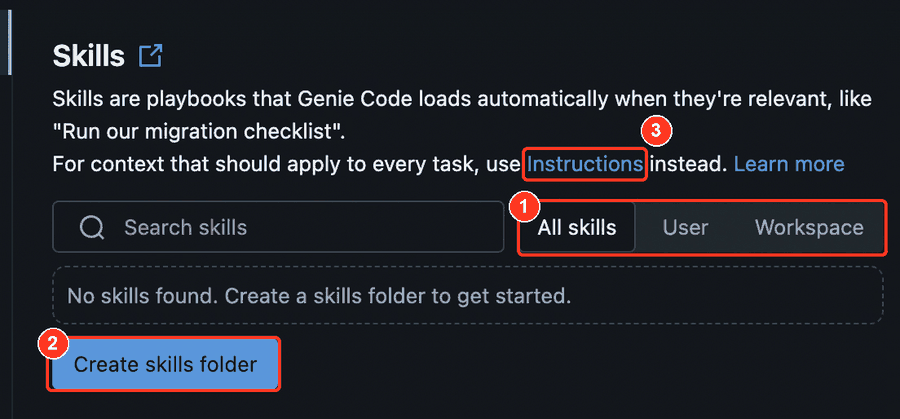

1. Filter the list by **User** or **Workspace**.
   - **User skills** live in `/Users/<you>/.assistant/skills/`. Only you can use them.
   - **Workspace skills** live in `/Workspace/.assistant/skills/`. Every user in the workspace can use them.
2. **Create skills folder** sets up your skills folder the first time.
3. For rules that should apply to every task, use **Instructions** instead. The next section covers them.

### What a skill folder looks like

Each skill has its own folder with a `SKILL.md` file inside. The `description` tells Genie Code when to load the skill, so write it the way a user would ask. The body holds the steps.

```
/Users/<you>/.assistant/skills/
  medallion-from-raw/
    SKILL.md
```

```markdown
---
name: medallion-from-raw
description: Build and run a bronze, silver, gold Spark Declarative Pipeline from raw tables. Use when the user asks for a medallion pipeline.
---

# Medallion pipeline from raw tables

If the user did not give them, ask for the source schema, the target schema and the gold tables they want.

1. Explore the source tables: schemas, sample rows and grain.
2. Bronze: ingest each source table as-is.
3. Silver: dimension tables and daily fact tables.
4. Gold: the tables the user asked for, with the exact names they gave.
5. Write the pipeline in SQL with full catalog.schema.table names, then run it.
6. Show 10 rows and the row count of each gold table.
```

### Create the skill with Genie Code

You do not need to write the file by hand. In the same chat as your pipeline, ask:

````
Create a user skill called medallion-from-raw based on the pipeline you built. It should take a source schema, a target schema and a short description of the gold tables I want, then build and run a bronze, silver, gold Spark Declarative Pipeline the same way. Save it in my .assistant/skills folder.
````

Then test it:
1. Open **⋮ > Customizations > Skills** and check that `medallion-from-raw` appears under **User**.
2. Start a **new chat**. Edits to a skill apply only in new chats.
3. Type `@medallion-from-raw` followed by a new request, for example a pipeline with one gold table of monthly revenue per retailer.

Docs: [Extend Genie Code with agent skills](https://docs.databricks.com/aws/en/genie-code/skills)

---
## Instructions: rules for every chat

Instructions are context Genie Code reads at the start of every conversation: coding conventions, project layout, preferred libraries and your role.

Find them in **⋮ > Customizations > Instructions**:

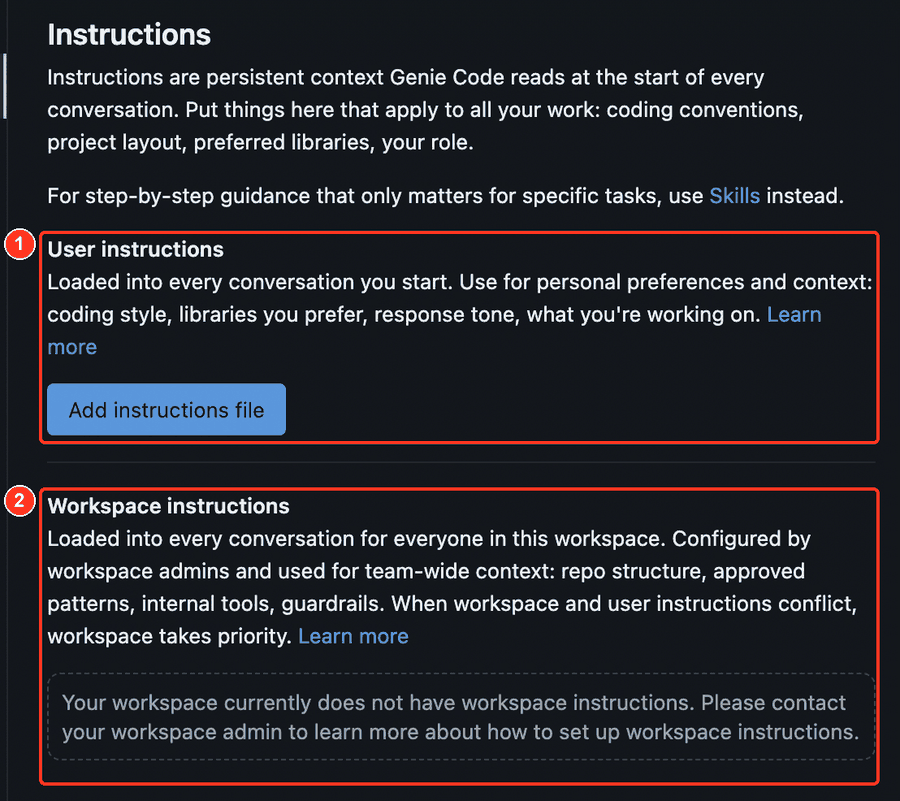

1. **User instructions** apply to every conversation you start. Click **Add instructions file** to create `/Users/<you>/.assistant_instructions.md`, then write your preferences in it.
2. **Workspace instructions** apply to every user in the workspace. Only workspace admins can edit that file, `/Workspace/.assistant_workspace_instructions.md`. When the two files conflict, the workspace file wins.

Instruction files are limited to 20,000 characters.

### Instructions or skills?

| | Instructions | Skills |
| --- | --- | --- |
| Loaded | At the start of every conversation | When your request matches the skill, or when you call it with `@` |
| Good for | Conventions for all your work | Step-by-step playbooks for one kind of task |
| Example | Always use full catalog.schema.table names | `medallion-from-raw` |
| Files | One file for you, one for the workspace | One folder per skill, with a `SKILL.md` inside |

### Try it

Click **Add instructions file** and paste this:

```markdown
# My Genie Code instructions
- Write Spark Declarative Pipelines in SQL.
- Always use full catalog.schema.table names.
- Write only to my own schema in genie_workshop_catalog. Never write to crisp_retail_distribution_data.
- Before each step, explain in one sentence what you are about to do.
```

Start a new chat and ask Genie Code: *"Which instructions are you following?"*

Docs: [Customize Genie Code with instructions](https://docs.databricks.com/aws/en/genie-code/instructions)

---
## Schedules: run a check every morning

**Scenario:** you own your CPG Retail Analytics Pipeline. Before the 9:00 stand-up, you want to know whether the latest update worked and whether the gold tables still have data, without opening the pipeline page. A scheduled task runs that check for you every morning.

Open **⋮ > Schedules**:

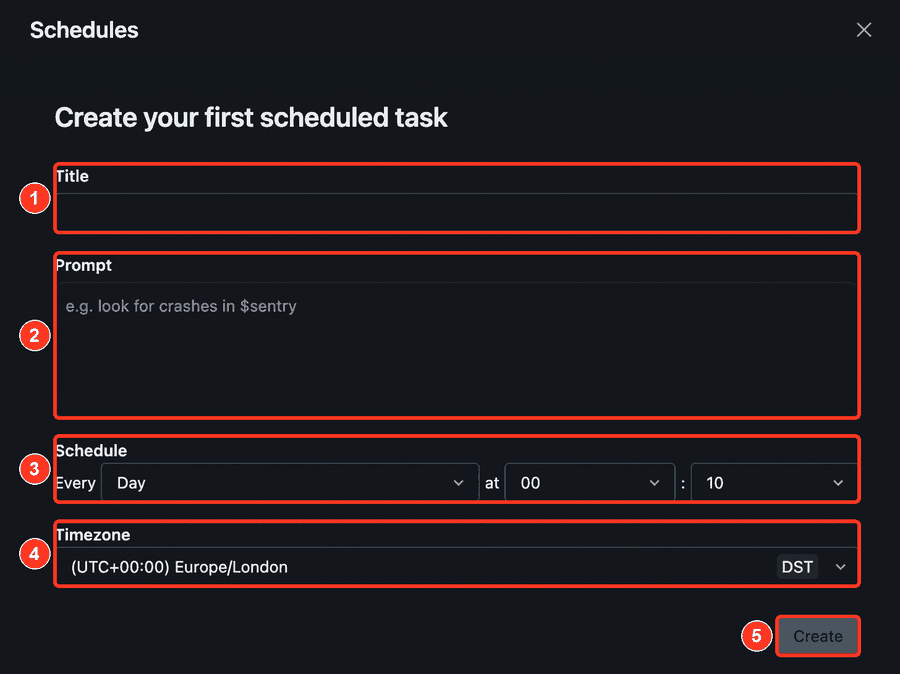

1. **Title**: `Morning pipeline check`
2. **Prompt**: paste the prompt below and replace `<pipeline_name>` and `<target_schema>` with the values the names cell printed.
3. **Schedule**: every **Day** at **07** : **00**
4. **Timezone**: your own, for example **Europe/London**
5. Click **Create**.

````
Check the latest update of the pipeline "<pipeline_name>".
Tell me whether it succeeded. If it failed, read the error and suggest a fix.
Then count the rows in gold_sales_velocity, gold_inventory_health and gold_supply_chain_coverage in <target_schema>, and flag any table with 0 rows.
Do not create, change or delete anything.
````

How scheduled tasks behave:
- Each run creates a new chat with the result.
- A run uses your permissions, so it sees the same data you do.
- Scheduled runs always auto-approve their actions, whatever you set under **Actions**. That is why the prompt ends with "Do not create, change or delete anything."
- Each run counts toward your Genie usage.

When you finish the lab, delete the task so it stops running.

Docs: [Scheduled tasks](https://docs.databricks.com/aws/en/genie-code/scheduled-tasks)

### Tips

**Give Genie Code the right context**
- **Point at assets with `@`.** Type `@` in the chat and pick a table, pipeline, notebook, query or file, for example `@harmonized_retailer_sales`. In a notebook, type `@cell` and pick the cell you mean.
- **Attach what text cannot say.** Paste or drag an image into the chat, such as a screenshot of an error or a sketch of the gold tables you want. Genie Code already sees the images and charts in your workspace notebooks and files, so attach only images from outside the workspace.
- **Attach sample files.** Genie Code accepts .png, .jpg, .jpeg, .gif, .webp, .pdf, .csv, .xlsx, .xls, .json and .jsonl files. It uses an attachment only in the current chat. Ask it to save the file to your workspace if you need it later.
- **Find tables before you name them.** Ask *"Find tables about store inventory"* or type `/findTables`.
- **Document your tables in Unity Catalog.** Table and column comments tell Genie Code what the data means, and a line of sample data in a comment helps it more. Try: *"Add table and column comments to the three gold tables in the pipeline code, then re-run the pipeline."* The Genie Agent you build in Act 2 reads these comments too.

**Write and review prompts**
- **Be specific.** Name the language, the level of detail and the format you want, for example *"Answer in SQL and show the result as a table of table name, grain and row count."*
- **Iterate in the same chat.** Ask Genie Code to change its last answer instead of rewriting the whole prompt.
- **Press Shift + Enter for a new line** in the chat box, so you can write a prompt over several lines before you send it.
- **Read the SQL before you approve.** Open the gold files in the pipeline editor and check the joins and aggregations.
- **If the run fails**, tell Genie Code: *"The pipeline update failed. Read the error, fix it and re-run."*

**Lab**
- **Lab environment reset**: Vocareum wipes lab outputs when your session expires. If your gold tables are gone, run the prompt again or call `@medallion-from-raw`.

Docs: [Tips to improve Genie Code responses](https://docs.databricks.com/aws/en/genie-code/tips)

---
## Next

Once the three gold tables exist, open **`Optional_02_AIBI_Dashboard`** if you have time, then go to **`01_Create_a_Genie_Agent`** in the Genie Agent folder.